# Peloton class engagement
**Group 5 — analysis complete, team details pending**  
**Members:** Connor Gossner, Mckayla Lollar, Addison Crosby, Carter Allen, John Michaels  
**Presentation video:** Add the recorded 8–10 minute video link here.

Our project examines which Peloton class characteristics are associated with higher usage. Using publicly available Peloton class data, we explore patterns across class lengths, workout types, instructors, and release dates.

We compare logistic regression, a decision tree, and K nearest neighbors to predict whether a class meets our high-usage threshold of at least 20,000 reported workouts. Our goal is to identify patterns that could help Peloton plan and promote its classes. The analysis focuses on historical class usage; it does not measure customer cancellations or show whether certain classes improve retention.

## 1 Business understanding
Peloton sells connected fitness equipment and subscriptions that give members access to workout classes. Understanding how class usage differs could help the company decide which content to offer and promote.

Peloton reported 2.553 million ending paid Connected Fitness subscriptions in Q4 FY2026, down 8.8% year over year [2]. Independent reporting describes membership pressure [3]. Net subscriber change is not a churn rate. Our historical catalog cannot explain current subscriber changes.

Our business question is: Which Peloton class characteristics are associated with higher reported usage? We examine class length, workout type, instructor, and release date to identify patterns and compare three prediction models.

Our goal is to predict high usage on class records that were not used to train the models and use the findings to suggest a content experiment. Because the dataset contains historical class records rather than individual customer activity, we cannot determine whether a class prevents cancellations or improves customer retention.

## 2 Sources
1. [Mark Byrne — Peloton Data source description](https://github.com/markbyrne/Peloton-Data#readme). Third party collection sourced from the Peloton API. The file is workouts.csv; one row is a class. It is not an official customer dataset.
2. [Peloton — Q4 and FY2026 results, August 6, 2026](https://onepeloton.gcs-web.com/news-releases/news-release-details/peloton-announces-q4-fy2026-financial-results). Company background source.
3. [Nathan Bomey, Axios — Peloton expands treadmill lineup, September 22, 2026](https://www.axios.com/2026/09/22/peloton-expands-treadmill-lineup-in-bid-to-regain-momentum). Independent business source.

Our analysis uses the Peloton class dataset collected by Mark Byrne and shared on GitHub. Each row represents a class, with information such as its length, workout type, instructor, release date, and reported usage. This is a third-party collection of Peloton data, not an official customer dataset.

We use Peloton’s financial results and the Axios article for business background. These sources provide context about the company, while the class dataset supplies the records used in our charts and prediction models.

## 3 Acquisition and data understanding
### Step 1 — Load basic tools

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
import hashlib
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
Path("figures").mkdir(exist_ok=True)

### Step 2 — Load the data
We load the Peloton class dataset and preview its structure.

In [34]:
data_path = Path("data/workouts.csv")
url = "https://raw.githubusercontent.com/markbyrne/Peloton-Data/main/datasets/workouts.csv"

if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(url, low_memory=False).to_csv(data_path, index=False)

raw = pd.read_csv(data_path, low_memory=False)
print("Rows and columns:", raw.shape)
print("SHA256:", hashlib.sha256(data_path.read_bytes()).hexdigest())
display(raw.head(3))

Rows and columns: (32528, 73)
SHA256: 90443a1024a56a3a1dd0949bc137920e6ff26d3b8e6c733d6fe6b910f86adec2


,id,availability,class_type_ids,content_provider,content_format,description,difficulty_estimate,overall_estimate,difficulty_rating_avg,difficulty_rating_count,...,thumbnail_title,thumbnail_location,distance,distance_unit,distance_display_value,muscle_group_score,is_sessions_eligible,total_user_workouts,total_following_workouts,is_favorite
0,d70e8e47a5be45f7aed2c8d9744cc94c,"{'is_available': True, 'reason': None}",['a9456fd677744f2ab9504d4accae96fd'],peloton,video,Run to the beat of a high-energy pop playlist ...,6.6279,1.0,6.6279,43,...,NaN,NaN,NaN,NaN,NaN,[],False,0,0,False
1,85dea6c843a143dca489d73a1d59fee0,"{'is_available': True, 'reason': None}",['59a49f882ea9475faa3110d50a8fb3f3'],peloton,video,This class is spent primarily in the saddle to...,6.2143,1.0,6.2143,308,...,NaN,NaN,NaN,NaN,NaN,[],True,0,0,False
2,9631041632fd488b80f5a8aacd69fb7d,"{'is_available': True, 'reason': None}",['6f3663cb0c4840f2bd51661695e481d2'],peloton,video,Fitness is for everyone! This class is specifi...,5.4412,1.0,5.4412,34,...,NaN,NaN,NaN,NaN,NaN,[],False,0,0,False


### Step 3 — Inspect the relevant fields

In [36]:
fields = ["id", "duration", "fitness_discipline", "instructor_id", "original_air_time", "total_workouts"]
display(raw[fields].dtypes.to_frame("Type"))
display(raw[fields].isna().sum().to_frame("Missing"))
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate class IDs:", raw.id.duplicated().sum())

,Type
id,object
duration,int64
fitness_discipline,object
instructor_id,object
original_air_time,int64
total_workouts,int64


,Missing
id,0
duration,0
fitness_discipline,0
instructor_id,0
original_air_time,0
total_workouts,0


Duplicate rows: 0
Duplicate class IDs: 0


### Step 4 — Inspect numeric ranges and catalog coverage

In [37]:
display(raw[["duration", "original_air_time", "total_workouts"]].describe())
display(raw.fitness_discipline.value_counts().to_frame("Classes"))
print("Usage values:", sorted(raw.total_workouts.unique()))
print("Archived flags:", raw.is_archived.value_counts().to_dict())

,duration,original_air_time,total_workouts
count,32528.000000,3.252800e+04,3.252800e+04
mean,1498.561240,1.615291e+09,3.863006e+04
std,757.885807,3.374826e+07,7.195155e+04
min,300.000000,1.538759e+09,0.000000e+00
25%,1200.000000,1.582636e+09,5.000000e+03
50%,1200.000000,1.619094e+09,2.000000e+04
75%,1800.000000,1.644496e+09,5.000000e+04
max,5400.000000,1.670096e+09,4.000000e+06


,Classes
fitness_discipline,
cycling,13042
yoga,4893
strength,4696
running,3923
meditation,1693
walking,1446
circuit,1077
stretching,797
cardio,547


Usage values: [np.int64(0), np.int64(100), np.int64(500), np.int64(1000), np.int64(5000), np.int64(10000), np.int64(20000), np.int64(30000), np.int64(40000), np.int64(50000), np.int64(60000), np.int64(70000), np.int64(80000), np.int64(90000), np.int64(100000), np.int64(150000), np.int64(200000), np.int64(250000), np.int64(300000), np.int64(350000), np.int64(400000), np.int64(450000), np.int64(500000), np.int64(550000), np.int64(600000), np.int64(650000), np.int64(700000), np.int64(750000), np.int64(800000), np.int64(850000), np.int64(900000), np.int64(950000), np.int64(1000000), np.int64(1500000), np.int64(2000000), np.int64(4000000)]
Archived flags: {True: 32528}


The dataset contains 32,528 classes and 73 columns. Workout counts are rounded and do not represent unique customers. All records are marked as archived, so the findings describe this historical snapshot rather than Peloton’s current catalog.

## 4 Data preparation
### Step 5 — Clean identifiers and numeric values

In [38]:
df = raw[fields].copy()
for col in ["duration", "original_air_time", "total_workouts"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["id", "total_workouts"]).drop_duplicates("id")
df = df.loc[(df.total_workouts >= 0) & (df.duration > 0)].copy()
print("Rows removed:", len(raw) - len(df))

Rows removed: 0


### Step 6 — Create useful class characteristics

In [39]:
df["air_date"] = pd.to_datetime(df.original_air_time, unit="s", utc=True, errors="coerce")
df["minutes"] = df.duration / 60
df["air_year"] = df.air_date.dt.year
df["air_month"] = df.air_date.dt.month.astype("str")
df["air_weekday"] = df.air_date.dt.day_name()
print("Air date range:", df.air_date.min(), "to", df.air_date.max())

Air date range: 2018-10-05 16:56:00+00:00 to 2022-12-03 19:25:00+00:00


### Step 7 — Define the answer
We label classes with at least 20,000 reported workouts as high usage. This is our project’s definition, not an official Peloton standard.

In [40]:
df["high_usage"] = (df.total_workouts >= 20000).astype(int)
display(df.high_usage.value_counts().rename_axis("High usage").to_frame("Classes"))
print("High usage share:", round(df.high_usage.mean(), 3))

,Classes
High usage,
1,17686
0,14842


High usage share: 0.544


### Step 8 — Hold out the test data
We use class length, workout type, instructor, release year, month, and weekday as inputs. We split the data into 80% training and 20% testing, keeping similar proportions of high-usage classes in each group. This tests performance on unseen records from the historical catalog, not future classes.

In [41]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
numeric = ["minutes", "air_year"]
categorical = ["fitness_discipline", "instructor_id", "air_month", "air_weekday"]
X, y = df[numeric + categorical], df.high_usage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
eda = df.loc[X_train.index].copy()
print("Training:", len(X_train), "Test:", len(X_test))

Training: 26022 Test: 6506


### Step 9 — Explore training records only

In [42]:
display(eda.groupby("fitness_discipline").agg(classes=("id", "size"), high_usage_share=("high_usage", "mean")).round(3))
display(eda.groupby("air_year").high_usage.mean().round(3))

,classes,high_usage_share
fitness_discipline,,
bike_bootcamp,226,0.960
caesar,86,0.000
caesar_bootcamp,35,0.000
cardio,435,0.752
circuit,851,0.133
cycling,10401,0.735
meditation,1337,0.515
running,3144,0.125
strength,3768,0.798


,high_usage
air_year,
2018,1.000
2019,0.279
2020,0.643
2021,0.647
2022,0.546


### Step 10 — Prepare missing values and categories
We fill missing values, convert categories into numeric inputs, and scale numeric features for logistic regression and KNN. These steps learn from the training data within each validation fold to prevent information from leaking into model evaluation.

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
num_steps = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
cat_steps = Pipeline([("fill", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))])
prep = ColumnTransformer([("numeric", num_steps, numeric), ("category", cat_steps, categorical)])

## 5 Modeling
We compare logistic regression, a decision tree, and K nearest neighbors to classify high-usage classes. Logistic regression estimates probabilities, the decision tree identifies classification rules, and KNN uses the labels of similar classes.

### Step 11 — Set the comparison rules
We use three-fold cross-validation to compare model settings on the training data. We select the model with the highest average validation F1 score, which balances precision and recall. We save the test data for the final evaluation.

We test different regularization settings for logistic regression, tree depths and minimum leaf sizes for the decision tree, and numbers of neighbors for KNN.

In [44]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
searches = {}

### Step 12 — Logistic regression


In [45]:
pipe = Pipeline([("prepare", clone(prep)), ("model", LogisticRegression(max_iter=1000, random_state=42))])
search = GridSearchCV(pipe, {"model__C": [.1, 1, 10]}, scoring="f1", cv=cv, n_jobs=1)
search.fit(X_train, y_train)
searches["Logistic regression"] = search
print("Best settings:", search.best_params_)
print("Validation F1:", round(search.best_score_, 4))

Best settings: {'model__C': 10}
Validation F1: 0.8417


### Step 13 — Decision tree


In [46]:
pipe = Pipeline([("prepare", clone(prep)), ("model", DecisionTreeClassifier(random_state=42))])
search = GridSearchCV(pipe, {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [10, 30]}, scoring="f1", cv=cv, n_jobs=1)
search.fit(X_train, y_train)
searches["Decision tree"] = search
print("Best settings:", search.best_params_)
print("Validation F1:", round(search.best_score_, 4))

Best settings: {'model__max_depth': 8, 'model__min_samples_leaf': 10}
Validation F1: 0.8483


### Step 14 — K nearest neighbors


In [14]:
pipe = Pipeline([("prepare", clone(prep)), ("model", KNeighborsClassifier(n_jobs=1))])
search = GridSearchCV(pipe, {"model__n_neighbors": [5, 15, 25]}, scoring="f1", cv=cv, n_jobs=1)
search.fit(X_train, y_train)
searches["K nearest neighbors"] = search
print("Best settings:", search.best_params_)
print("Validation F1:", round(search.best_score_, 4))

Best settings: {'model__n_neighbors': 15}
Validation F1: 0.857


### Step 15 — Compare tuning attempts and select the winner

In [15]:
for name, search in searches.items():
    print(name)
    display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]].round(4))
winner = max(searches, key=lambda name: searches[name].best_score_)
print("Selected before test evaluation:", winner)
comparison = pd.DataFrame({k: {"CV F1": v.best_score_, "CV SD": v.cv_results_["std_test_score"][v.best_index_]} for k, v in searches.items()}).T
comparison.to_csv("validation_results.csv")

Logistic regression


,params,mean_test_score,std_test_score
0,{'model__C': 0.1},0.8336,0.0061
1,{'model__C': 1},0.8408,0.0051
2,{'model__C': 10},0.8417,0.0053


Decision tree


,params,mean_test_score,std_test_score
0,"{'model__max_depth': 3, 'model__min_samples_le...",0.8002,0.0114
1,"{'model__max_depth': 3, 'model__min_samples_le...",0.8002,0.0114
2,"{'model__max_depth': 5, 'model__min_samples_le...",0.8256,0.0114
3,"{'model__max_depth': 5, 'model__min_samples_le...",0.8265,0.0130
4,"{'model__max_depth': 8, 'model__min_samples_le...",0.8483,0.0073
5,"{'model__max_depth': 8, 'model__min_samples_le...",0.8457,0.0056


K nearest neighbors


,params,mean_test_score,std_test_score
0,{'model__n_neighbors': 5},0.8497,0.0046
1,{'model__n_neighbors': 15},0.8570,0.0047
2,{'model__n_neighbors': 25},0.8555,0.0036


Selected before test evaluation: K nearest neighbors


## 6 Evaluation
### Step 16 — Evaluate fixed models and a baseline
We compare the models using accuracy, precision, recall, and F1. Precision measures how often a predicted high-usage class actually meets the threshold, while recall measures how many high-usage classes the model identifies. We also compare against a simple baseline that always predicts the most common training label.

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
models = {name: search.best_estimator_ for name, search in searches.items()}
predictions = {name: model.predict(X_test) for name, model in models.items()}
predictions["Majority baseline"] = np.full(len(y_test), y_train.mode()[0])
rows = []
for name, pred in predictions.items():
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0), recall_score(y_test, pred), f1_score(y_test, pred)])
results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).set_index("Model")
display(results.round(4))
results.to_csv("model_results.csv")

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic regression,0.8245,0.8204,0.8668,0.8430
Decision tree,0.8431,0.8290,0.8962,0.8613
K nearest neighbors,0.8420,0.8495,0.8620,0.8557
Majority baseline,0.5437,0.5437,1.0000,0.7044


### Step 17 — Understand the selected model’s mistakes

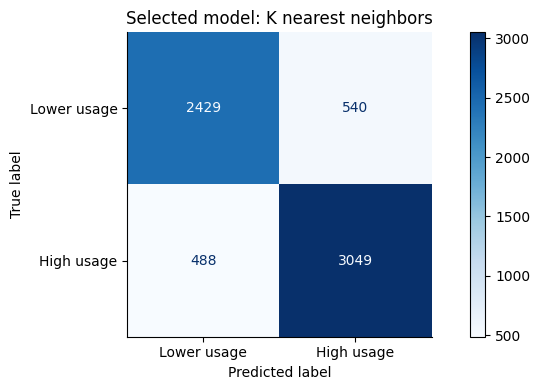

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions[winner], display_labels=["Lower usage", "High usage"], cmap="Blues")
plt.title("Selected model: " + winner)
plt.tight_layout()
plt.savefig("figures/test_confusion_matrix.png", dpi=160)
plt.show()

### Step 18 — Translate results into business language

In [18]:
score = results.loc[winner]
display(Markdown(f"**{winner}** was selected using validation F1. On the test set, accuracy was **{score.Accuracy:.1%}**, precision **{score.Precision:.1%}**, recall **{score.Recall:.1%}**, and F1 **{score.F1:.3f}**. Of every 100 classes labeled high usage, approximately {100*score.Precision:.0f} actually met our threshold. These scores apply only to held out classes in this historical catalog."))

**K nearest neighbors** was selected using validation F1. On the test set, accuracy was **84.2%**, precision **85.0%**, recall **86.2%**, and F1 **0.856**. Of every 100 classes labeled high usage, approximately 85 actually met our threshold. These scores apply only to held out classes in this historical catalog.

### Step 19 — Check performance across air years

In [19]:
errors = X_test[["air_year"]].copy()
errors["correct"] = predictions[winner] == y_test.to_numpy()
display(errors.groupby("air_year").agg(classes=("correct", "size"), accuracy=("correct", "mean")).round(3))

,classes,accuracy
air_year,,
2018,2,1.000
2019,1330,0.842
2020,1396,0.796
2021,1949,0.872
2022,1829,0.845


A false positive labels a class as high usage when it falls below our threshold. A false negative misses a class that meets the threshold. Performance may vary across release years because classes had different amounts of time and promotion to attract usage. These results do not show that particular class features cause higher usage or prevent cancellations.

## 7 Final descriptive charts
These six charts explore class characteristics and reported usage using the training data. High usage means at least 20,000 reported workouts.

### Step 20 — Classes by discipline

Cycling is the most common workout type in this dataset, but the number of available classes does not tell us which types members prefer.

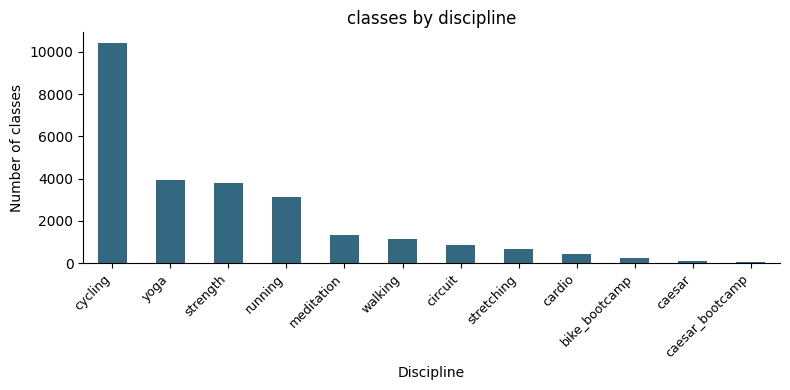

In [20]:
values = eda.fitness_discipline.value_counts()
ax = values.plot.bar(color="#346780")
ax.set(title="classes by discipline", xlabel="Discipline", ylabel="Number of classes")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig("figures/chart_1.png", dpi=160)
plt.show()

### Step 21 — Classes by length

Twenty- and thirty-minute classes are the most common lengths in the training data.

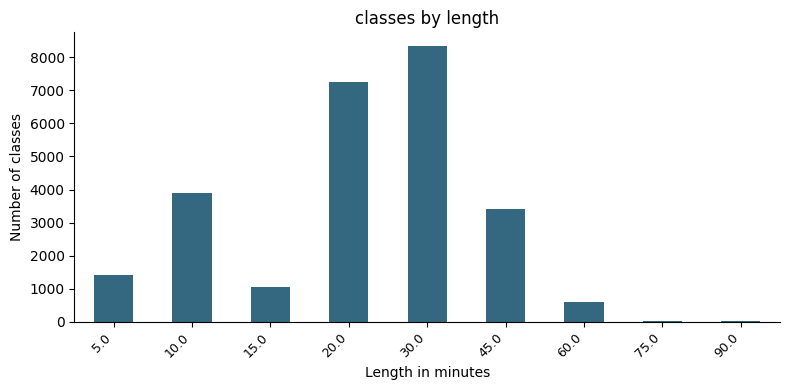

In [21]:
values = eda.minutes.value_counts().sort_index()
ax = values.plot.bar(color="#346780")
ax.set(title="classes by length", xlabel="Length in minutes", ylabel="Number of classes")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig("figures/chart_2.png", dpi=160)
plt.show()

### Step 22 — Reported usage distribution

Reported usage varies widely across classes, and the rounded counts should not be interpreted as exact attendance.

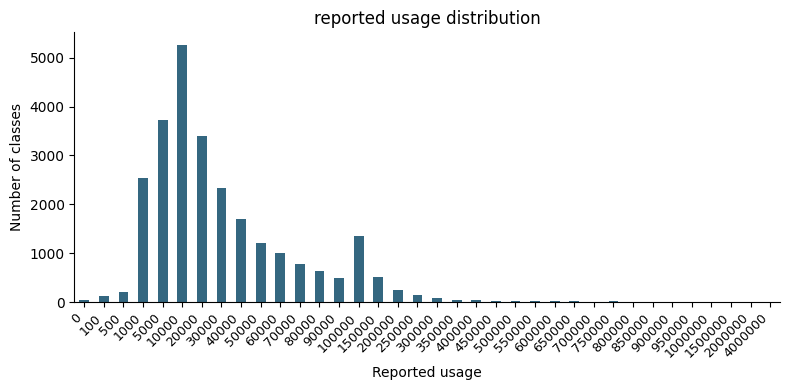

In [22]:
values = eda.total_workouts.value_counts().sort_index()
ax = values.plot.bar(color="#346780")
ax.set(title="reported usage distribution", xlabel="Reported usage", ylabel="Number of classes")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig("figures/chart_3.png", dpi=160)
plt.show()

### Step 23 — High usage share by discipline

The percentage of high-usage classes differs across workout types, although audience size, promotion, and time available may help explain these differences.

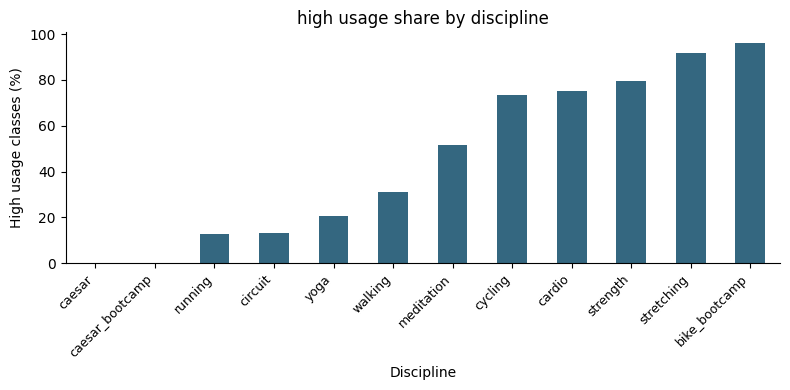

In [23]:
values = eda.groupby("fitness_discipline").high_usage.mean().sort_values() * 100
ax = values.plot.bar(color="#346780")
ax.set(title="high usage share by discipline", xlabel="Discipline", ylabel="High usage classes (%)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig("figures/chart_4.png", dpi=160)
plt.show()

In [24]:
display(values.round(1).to_frame("Percent high usage"))

,Percent high usage
fitness_discipline,
caesar,0.0
caesar_bootcamp,0.0
running,12.5
circuit,13.3
yoga,20.6
walking,31.0
meditation,51.5
cycling,73.5
cardio,75.2


### Step 24 — Cycling high usage share by length

Within cycling, high-usage percentages vary by class length, but this comparison alone does not show that a particular length leads to higher usage.

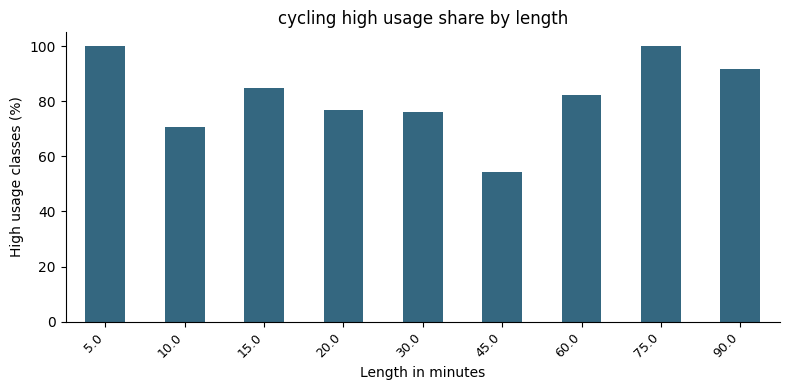

In [25]:
values = eda.loc[eda.fitness_discipline.eq("cycling")].groupby("minutes").high_usage.mean() * 100
ax = values.plot.bar(color="#346780")
ax.set(title="cycling high usage share by length", xlabel="Length in minutes", ylabel="High usage classes (%)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig("figures/chart_5.png", dpi=160)
plt.show()

In [26]:
display(values.round(1).to_frame("Percent high usage"))

,Percent high usage
minutes,
5.0,100.0
10.0,70.6
15.0,84.7
20.0,76.9
30.0,76.2
45.0,54.2
60.0,82.3
75.0,100.0
90.0,91.7


### Step 25 — High usage share by air year

High-usage percentages vary across release years without a consistent trend; the 2018 result is based on only three classes.

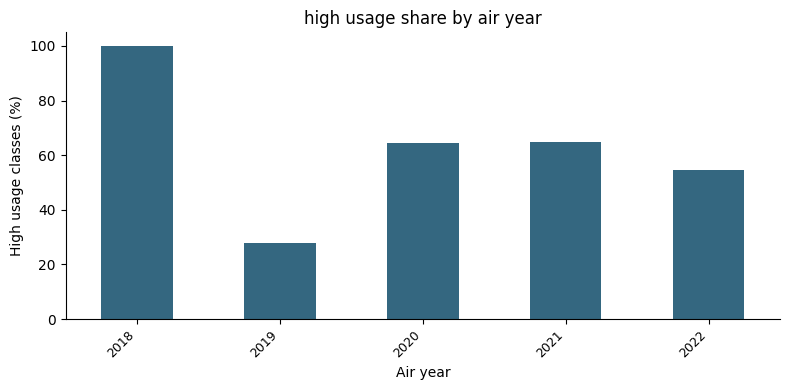

In [27]:
values = eda.groupby("air_year").high_usage.mean() * 100
ax = values.plot.bar(color="#346780")
ax.set(title="high usage share by air year", xlabel="Air year", ylabel="High usage classes (%)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig("figures/chart_6.png", dpi=160)
plt.show()

In [28]:
display(values.round(1).to_frame("Percent high usage"))

,Percent high usage
air_year,
2018,100.0
2019,27.9
2020,64.3
2021,64.7
2022,54.6


### Supporting counts and fairer class comparisons
We check group sizes and compare cycling class lengths within the same release year to see whether the overall pattern holds. We interpret only length-and-year groups with at least 50 classes.

In [29]:
discipline_summary = eda.groupby("fitness_discipline").agg(n=("id", "size"), share=("high_usage", "mean"))
year_summary = eda.groupby("air_year").agg(n=("id", "size"), share=("high_usage", "mean"))
cycling = eda.loc[eda.fitness_discipline.eq("cycling")]
length_summary = cycling.groupby("minutes").agg(n=("id", "size"), share=("high_usage", "mean"))
display(discipline_summary.round(3))
display(year_summary.round(3))
display(length_summary.round(3))

,n,share
fitness_discipline,,
bike_bootcamp,226,0.960
caesar,86,0.000
caesar_bootcamp,35,0.000
cardio,435,0.752
circuit,851,0.133
cycling,10401,0.735
meditation,1337,0.515
running,3144,0.125
strength,3768,0.798


,n,share
air_year,,
2018,3,1.000
2019,5162,0.279
2020,5922,0.643
2021,7371,0.647
2022,7564,0.546


,n,share
minutes,,
5.0,272,1.000
10.0,511,0.706
15.0,515,0.847
20.0,2759,0.769
30.0,4268,0.762
45.0,1826,0.542
60.0,226,0.823
75.0,12,1.000
90.0,12,0.917


In [30]:
within_year = cycling.groupby(["air_year", "minutes"]).agg(n=("id", "size"), share=("high_usage", "mean"))
display(within_year.loc[within_year.n >= 50].round(3))
within_year.to_csv("cycling_length_by_year.csv")

n  share
air_year minutes             
2019     10.0      192  0.292
         15.0       89  0.596
         20.0      523  0.377
         30.0      820  0.416
         45.0      832  0.172
         60.0       66  0.576
2020     5.0        86  1.000
         10.0       92  0.935
         15.0      141  0.901
         20.0      652  0.775
         30.0     1139  0.806
         45.0      463  0.786
         60.0       55  0.909
2021     5.0        78  1.000
         10.0      102  0.980
         15.0      145  0.979
         20.0      863  0.934
         30.0     1134  0.903
         45.0      300  0.953
         60.0       66  1.000
2022     5.0        70  1.000
         10.0      125  0.952
         15.0      140  0.814
         20.0      721  0.850
         30.0     1175  0.824
         45.0      231  0.853

## 8 Conclusions and deployment plan
### Step 26 — Summarize descriptive evidence

In [31]:
counts = eda.fitness_discipline.value_counts()
shares = eda.groupby("fitness_discipline").high_usage.agg(["mean", "size"])
eligible = shares.loc[shares["size"] >= 100]
top = eligible["mean"].idxmax()
display(Markdown(f"**{counts.index[0]}** has the most classes in the training catalog ({counts.iloc[0]:,}). Among disciplines with at least 100 classes, **{top}** has the highest high usage share ({eligible.loc[top, 'mean']:.1%}). These are historical associations and may reflect promotion, audience size and time available."))

**cycling** has the most classes in the training catalog (10,401). Among disciplines with at least 100 classes, **bike_bootcamp** has the highest high usage share (96.0%). These are historical associations and may reflect promotion, audience size and time available.

**Main findings:** Class usage varies across workout types, lengths, and release years. Shorter cycling classes appear to have higher usage overall, but that pattern does not consistently hold when comparing classes from the same year. We therefore cannot recommend shorter classes based on this comparison alone.

**Model results:** KNN had the highest validation F1 score at 0.857, so we selected it before evaluating the test data. The decision tree performed slightly better on the test set, with an F1 of 0.861 compared with KNN’s 0.856. We report both results without changing our original selection.

**Recommendation:** Peloton could use these findings to select classes for a small promotion experiment. Randomly comparing featured classes against the usual selection would help determine whether the change improves participation and satisfaction over a fixed period.

**Before deployment:** The model needs newer data and testing on later release periods before being used to predict future class usage.

**Limitations:** This dataset contains historical classes from 2018–2022, rounded usage counts, and unequal time for classes to attract workouts. The results show associations, not causes, and cannot establish whether particular classes reduce customer cancellations.

## Reproduction record
These checks confirm that the training and test sets do not overlap, the model uses six inputs, and all six charts were saved. We also record the software versions used to run the analysis.

In [32]:
import sklearn, matplotlib, json, sys
assert set(X_train.index).isdisjoint(X_test.index)
assert X.shape[1] == 6 and y.nunique() == 2
assert len(list(Path("figures").glob("chart_*.png"))) == 6
versions = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
Path("environment.json").write_text(json.dumps(versions, indent=2))
print("Checks passed:", len(X_train), "training rows and", len(X_test), "test rows")
display(versions)

Checks passed: 26022 training rows and 6506 test rows


{'python': '3.13.18',
 'pandas': '2.2.3',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'matplotlib': '3.10.0'}

In [33]:
chart_data = {"discipline_counts": eda.fitness_discipline.value_counts().to_dict(), "length_counts": eda.minutes.value_counts().sort_index().to_dict(), "usage_counts": eda.total_workouts.value_counts().sort_index().to_dict()}
chart_data["discipline_share"] = (discipline_summary.share * 100).round(1).to_dict()
chart_data["cycling_length_share"] = (length_summary.share * 100).round(1).to_dict()
chart_data["year_share"] = (year_summary.share * 100).round(1).to_dict()
chart_data["sample_counts"] = {"discipline": discipline_summary.n.to_dict(), "cycling_length": length_summary.n.to_dict(), "year": year_summary.n.to_dict()}
Path("chart_data.json").write_text(json.dumps(chart_data, indent=2))
print("Presentation chart values saved.")

Presentation chart values saved.
